# **How to operate the files**
1. Connect to a runtime (T4 gpu is recommended).
2. On the left side go on files section and import the rest of the files ( data_pipeline, short_eng_fra_50k.txt).
3. Run the first 2 blocks and if you are satisfied with the result run the next block after to test out the custom inputs with the model.

# Importing required libraries and Defining the model pipeline.
*  You can play with the parameters in the config section to further fine tune
the model.
The batch size is taken small because of the ram usage, you can take it even smaller.
* Using a vanilla RNN can show how much room there is to improve upon, using LSTM or GRU here can drastically improve the output capabilites of the model.
Due to the small dataset the model is prone to give out wrong output during the translation.

In [ ]:


import random

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

from data_pipeline import prepare_data, SOS_TOKEN, EOS_TOKEN

# ----------------------------
# Config
# ----------------------------
PAD_IDX = 0          # Vocabulary always assigns <pad> -> index 0 (see data_pipeline.Vocabulary)
EMBED_SIZE = 256
HIDDEN_SIZE = 512
NUM_LAYERS = 1
DROPOUT = 0.1
LEARNING_RATE = 1e-3
CLIP = 1.0
TEACHER_FORCING_RATIO = 0.5
NUM_EPOCHS = 10
BATCH_SIZE = 256        # small on purpose -- adjust upward once using the full corpus

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ----------------------------
# Encoder
# ----------------------------
class Encoder(nn.Module):
    def __init__(self, input_size, embed_size, hidden_size, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(input_size, embed_size, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(embed_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_lengths):
        # src: (batch, src_len)
        embedded = self.dropout(self.embedding(src))  # (batch, src_len, embed_size)

        # Packing tells the GRU to ignore <pad> positions rather than
        # running (and learning from) padding as if it were real input.
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, src_lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_outputs, hidden = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(packed_outputs, batch_first=True)

        # outputs: (batch, src_len, hidden_size) -- per-timestep states.
        #   Unused by this baseline; kept in the return signature so the
        #   attention model in the next stage can reuse this exact Encoder.
        # hidden:  (num_layers, batch, hidden_size) -- final state = the
        #   fixed-length context vector this baseline is built around.
        return outputs, hidden


# ----------------------------
# Decoder (baseline: no attention)
# ----------------------------
class DecoderBaseline(nn.Module):
    def __init__(self, output_size, embed_size, hidden_size, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(output_size, embed_size, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(embed_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc_out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_token, hidden):
        # input_token: (batch,) -- a single decoded token per sequence
        # hidden:      (num_layers, batch, hidden_size) -- carried from the
        #              previous step (or the encoder's final hidden state,
        #              on the very first step)
        input_token = input_token.unsqueeze(1)                # (batch, 1)
        embedded = self.dropout(self.embedding(input_token))  # (batch, 1, embed_size)
        output, hidden = self.rnn(embedded, hidden)            # output: (batch, 1, hidden_size)
        prediction = self.fc_out(output.squeeze(1))             # (batch, output_size)
        return prediction, hidden


# ----------------------------
# Seq2Seq wrapper (teacher forcing lives here)
# ----------------------------
class Seq2SeqBaseline(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, src_lengths, tgt, teacher_forcing_ratio=0.5):
        batch_size, tgt_len = tgt.shape
        tgt_vocab_size = self.decoder.fc_out.out_features

        outputs = torch.zeros(batch_size, tgt_len, tgt_vocab_size, device=self.device)

        # Baseline only uses the final hidden state -- the bottleneck this
        # project is designed to expose.
        _, hidden = self.encoder(src, src_lengths)

        # Every target sequence starts with <sos> (index 0 of tgt); feed
        # that in as the decoder's first input.
        input_token = tgt[:, 0]

        for t in range(1, tgt_len):
            prediction, hidden = self.decoder(input_token, hidden)
            outputs[:, t] = prediction

            teacher_force = random.random() < teacher_forcing_ratio
            top1 = prediction.argmax(1)
            # Teacher forcing: feed the *true* previous word instead of the
            # model's own (possibly wrong) prediction, which stabilizes
            # early training at the cost of a train/inference mismatch.
            input_token = tgt[:, t] if teacher_force else top1

        return outputs


# ----------------------------
# Build model / optimizer / loss
# ----------------------------
def build_model(src_vocab_size, tgt_vocab_size, device):
    encoder = Encoder(src_vocab_size, EMBED_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    decoder = DecoderBaseline(tgt_vocab_size, EMBED_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    model = Seq2SeqBaseline(encoder, decoder, device).to(device)
    return model


# ----------------------------
# Training / evaluation loops
# ----------------------------
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    epoch_loss = 0.0
    for src, tgt, src_lens, tgt_lens in loader:
        src, tgt = src.to(device), tgt.to(device)

        # Correctly clear the gradients from the previous batch
        optimizer.zero_grad()

        output = model(src, src_lens, tgt, TEACHER_FORCING_RATIO)

        output_dim = output.shape[-1]
        output = output[:, 1:].reshape(-1, output_dim)
        tgt_flat = tgt[:, 1:].reshape(-1)

        loss = criterion(output, tgt_flat)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        optimizer.step()

        epoch_loss += loss.item()
    return epoch_loss / len(loader)

def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    epoch_loss = 0.0
    with torch.no_grad():
        for src, tgt, src_lens, tgt_lens in loader:
            src, tgt = src.to(device), tgt.to(device)
            # teacher_forcing_ratio=0 -> model relies purely on its own
            # predictions, matching real inference conditions.
            output = model(src, src_lens, tgt, teacher_forcing_ratio=0.0)

            output_dim = output.shape[-1]
            output = output[:, 1:].reshape(-1, output_dim)
            tgt_flat = tgt[:, 1:].reshape(-1)

            loss = criterion(output, tgt_flat)
            epoch_loss += loss.item()
    return epoch_loss / len(loader)


# ----------------------------
# Greedy-decode a single sentence (for spot-checking translations)
# ----------------------------
def translate_sentence(model, sentence, src_vocab, tgt_vocab, device, max_len=20):
    model.eval()
    tokens = src_vocab.encode(sentence)  # already wraps with <sos>/<eos>
    src_tensor = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
    src_len = torch.tensor([len(tokens)])

    with torch.no_grad():
        _, hidden = model.encoder(src_tensor, src_len)

    input_token = torch.tensor([tgt_vocab.word2idx[SOS_TOKEN]], device=device)
    result_ids = []
    for _ in range(max_len):
        with torch.no_grad():
            prediction, hidden = model.decoder(input_token, hidden)
        top1 = prediction.argmax(1)
        if top1.item() == tgt_vocab.word2idx[EOS_TOKEN]:
            break
        result_ids.append(top1.item())
        input_token = top1

    return tgt_vocab.decode(result_ids)



class Attention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        # Matches the Bahdanau additive attention architecture
        self.attn = nn.Linear(hidden_size * 2, hidden_size)
        self.v = nn.Linear(hidden_size, 1, bias=False)

    def forward(self, hidden, encoder_outputs):
        # hidden shape: (1, batch, hidden_size) -> (batch, hidden_size)
        hidden = hidden.squeeze(0)
        seq_len = encoder_outputs.shape[1]

        # Repeat hidden state across the sequence length of the source sentence
        # shape: (batch, seq_len, hidden_size)
        hidden_expanded = hidden.unsqueeze(1).repeat(1, seq_len, 1)

        # Calculate energy: (batch, seq_len, hidden_size)
        energy = torch.tanh(self.attn(torch.cat((hidden_expanded, encoder_outputs), dim=2)))

        # Get attention scores: (batch, seq_len, 1) -> (batch, seq_len)
        attention_scores = self.v(energy).squeeze(2)

        # Apply softmax to convert scores to probabilities (weights)
        return F.softmax(attention_scores, dim=1)
class DecoderAttention(nn.Module):
    def __init__(self, output_size, embed_size, hidden_size, num_layers=1, dropout=0.1):
        super().__init__()
        self.attention = Attention(hidden_size)
        self.embedding = nn.Embedding(output_size, embed_size, padding_idx=PAD_IDX)

        # The GRU now takes the embedded token PLUS the context vector
        self.rnn = nn.GRU(embed_size + hidden_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc_out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_token, hidden, encoder_outputs):
        input_token = input_token.unsqueeze(1)
        embedded = self.dropout(self.embedding(input_token))

        # 1. Get attention weights: (batch, src_len)
        attn_weights = self.attention(hidden, encoder_outputs)
        attn_weights = attn_weights.unsqueeze(1) # (batch, 1, src_len)

        # 2. Multiply weights by encoder outputs to get context vector
        # bmm = batch matrix multiplication
        # (batch, 1, src_len) * (batch, src_len, hidden_size) -> (batch, 1, hidden_size)
        context = torch.bmm(attn_weights, encoder_outputs)

        # 3. Concatenate context vector and embedded input
        rnn_input = torch.cat((embedded, context), dim=2)

        # 4. Generate prediction
        output, hidden = self.rnn(rnn_input, hidden)
        prediction = self.fc_out(output.squeeze(1))

        # Return the attention weights so we can plot them later
        return prediction, hidden, attn_weights.squeeze(1)
class Seq2SeqAttention(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, src_lengths, tgt, teacher_forcing_ratio=0.5):
        batch_size, tgt_len = tgt.shape
        tgt_vocab_size = self.decoder.fc_out.out_features
        outputs = torch.zeros(batch_size, tgt_len, tgt_vocab_size, device=self.device)

        # Capture encoder_outputs alongside the hidden state
        encoder_outputs, hidden = self.encoder(src, src_lengths)
        input_token = tgt[:, 0]

        for t in range(1, tgt_len):
            # Pass encoder_outputs into the decoder
            prediction, hidden, _ = self.decoder(input_token, hidden, encoder_outputs)
            outputs[:, t] = prediction

            teacher_force = random.random() < teacher_forcing_ratio
            top1 = prediction.argmax(1)
            input_token = tgt[:, t] if teacher_force else top1

        return outputs
def translate_and_visualize(model, sentence, src_vocab, tgt_vocab, device, max_len=20):
    model.eval()
    tokens = src_vocab.encode(sentence)
    src_tensor = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
    src_len = torch.tensor([len(tokens)])

    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(src_tensor, src_len)

    input_token = torch.tensor([tgt_vocab.word2idx[SOS_TOKEN]], device=device)
    result_ids = []

    # Store attention weights for the heatmap
    attention_matrix = torch.zeros(max_len, len(tokens))

    for i in range(max_len):
        with torch.no_grad():
            prediction, hidden, attn_weights = model.decoder(input_token, hidden, encoder_outputs)

        # Save the attention weights for this specific decoded word
        attention_matrix[i] = attn_weights.squeeze().cpu()

        top1 = prediction.argmax(1)
        if top1.item() == tgt_vocab.word2idx[EOS_TOKEN]:
            break

        result_ids.append(top1.item())
        input_token = top1

    translated_sentence = tgt_vocab.decode(result_ids)

    # Trim the matrix to actual sequence lengths
    attention_matrix = attention_matrix[:len(result_ids), :].numpy()

    # --- Plotting the Heatmap ---
    fig, ax = plt.subplots(figsize=(8, 8))
    sns.heatmap(attention_matrix, cmap='viridis', ax=ax, cbar=True)

    # Set labels based on the actual words
    src_words = [src_vocab.idx2word[idx] for idx in tokens]
    tgt_words = translated_sentence.split()

    ax.set_xticks(range(len(src_words)))
    ax.set_yticks(range(len(tgt_words)))
    ax.set_xticklabels(src_words, rotation=45, ha="right", fontsize=12)
    ax.set_yticklabels(tgt_words, rotation=0, fontsize=12)

    plt.xlabel("Source Language (English)", fontsize=14)
    plt.ylabel("Target Language (French)", fontsize=14)
    plt.title("Attention Alignment Heatmap", fontsize=16)
    plt.tight_layout()
    plt.show()

    return translated_sentence

# ----------------------------
# Build Model (Updated for Attention)
# ----------------------------
def build_attention_model(src_vocab_size, tgt_vocab_size, device):
    # We reuse the exact same Encoder from the baseline
    encoder = Encoder(src_vocab_size, EMBED_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    # But we use our new Attention Decoder
    decoder = DecoderAttention(tgt_vocab_size, EMBED_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
    # And wrap them in the new Attention Seq2Seq wrapper
    model = Seq2SeqAttention(encoder, decoder, device).to(device)
    return model



# INITIALIZING MODEL AND TRAINING
* The dataset is loaded in this section.
* The output is shown with a heatmap with the relevant word during the translation and each epoch is logged and displayed.

❗NOTE   : This model is far from being used in any practical work, you can optimize and rework the model according to your likings and do many more, this is just a college project that was assigned to our group.



Loaded 50000 pairs from short_eng_fra_50k.txt
Train/Val/Test sizes: 40000/5000/5000
Source vocab size: 5493 | Target vocab size: 8350
Training ATTENTION seq2seq on cuda for 10 epochs...
Epoch  1 | train_loss=4.1488 | val_loss=3.5810
Epoch  2 | train_loss=2.8615 | val_loss=3.0235
Epoch  3 | train_loss=2.2185 | val_loss=2.6499
Epoch  4 | train_loss=1.7538 | val_loss=2.4350
Epoch  5 | train_loss=1.4267 | val_loss=2.2729
Epoch  6 | train_loss=1.1604 | val_loss=2.2493
Epoch  7 | train_loss=1.0035 | val_loss=2.2211
Epoch  8 | train_loss=0.8804 | val_loss=2.1816
Epoch  9 | train_loss=0.7809 | val_loss=2.2104
Epoch 10 | train_loss=0.6931 | val_loss=2.2521

Attention Heatmap Visualization


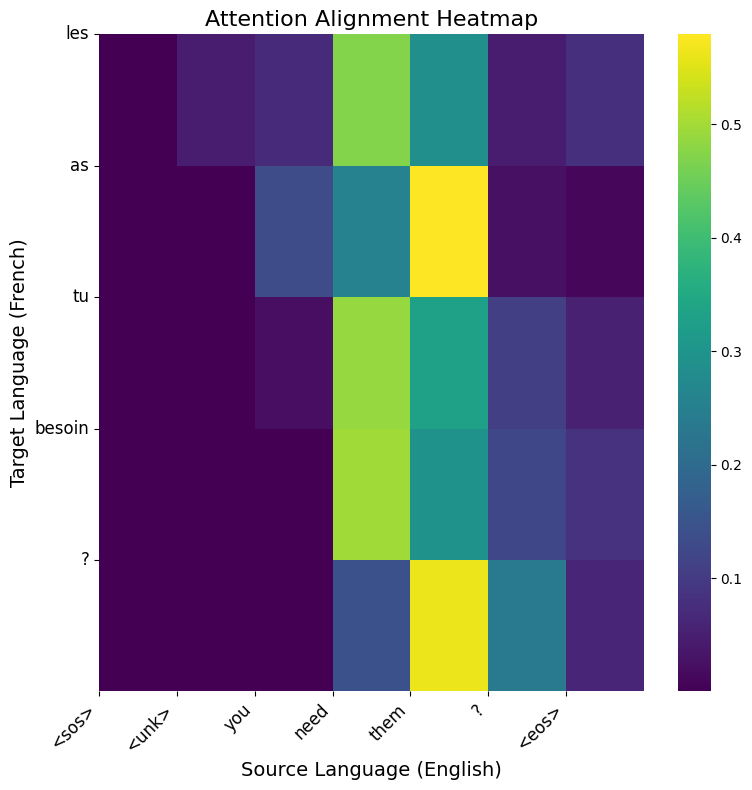

Source (en):  Do you need them ? 
Model output (fr): les as tu besoin ?


In [ ]:
# ----------------------------
# Run it
# ----------------------------
if __name__ == "__main__":
    # 1. Load the 20k dataset subset
    train_loader, val_loader, test_loader, src_vocab, tgt_vocab = prepare_data(
        batch_size=BATCH_SIZE,
        data_path="short_eng_fra_50k.txt"
    )
    #model, cleaned_eng, src_vocab, tgt_vocab, DEVICE
    #model, sentence, src_vocab, tgt_vocab, device, max_len=20

    # 2. Instantiate the ATTENTION model
    model = build_attention_model(len(src_vocab), len(tgt_vocab), DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

    print(f"Training ATTENTION seq2seq on {DEVICE} for {NUM_EPOCHS} epochs...")

    # 3. Training Loop
    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, DEVICE)
        val_loss = evaluate_epoch(model, val_loader, criterion, DEVICE)
        print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    # 4. Generate the Heatmap Visualization
    print("\n" + "="*30)
    print("Attention Heatmap Visualization")
    print("="*30)

    # Test sentence (must be clean and lowercase with separated punctuation)
    test_sentence = " Do you need them ? "



    # This function will translate the sentence AND pop up the matplotlib heatmap plot
    french_output = translate_and_visualize(model, test_sentence, src_vocab, tgt_vocab, DEVICE)

    print(f"Source (en): {test_sentence}")

    print(f"Model output (fr): {french_output}")

# Repeated Testing
After the training is done you can run this block to give custom inputs repeatedly to further test the model's performance.


In [ ]:
# ... (Your training loop finishes above this) ...

    # ----------------------------
    # 5. Interactive Testing Loop
    # ----------------------------
print("\n" + "="*30)
print("Interactive Translation Test")
print("="*30)

from data_pipeline import normalize_sentence

# A lightweight translation function without the matplotlib heatmap
def translate_only(model, sentence, src_vocab, tgt_vocab, device, max_len=20):
    model.eval()
    tokens = src_vocab.encode(sentence)
    src_tensor = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
    src_len = torch.tensor([len(tokens)])

    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(src_tensor, src_len)

    input_token = torch.tensor([tgt_vocab.word2idx[SOS_TOKEN]], device=device)
    result_ids = []

    for _ in range(max_len):
        with torch.no_grad():
            prediction, hidden, _ = model.decoder(input_token, hidden, encoder_outputs)

        top1 = prediction.argmax(1)
        if top1.item() == tgt_vocab.word2idx[EOS_TOKEN]:
            break

        result_ids.append(top1.item())
        input_token = top1

    return tgt_vocab.decode(result_ids)

# The actual continuous loop
while True:
    try:
        # Get user input
        user_input = input("Enter an English sentence (or type 'q' to quit): ")

        # Exit condition
        if user_input.lower().strip() == 'q':
            print("Exiting translator.")
            break

        # Skip empty inputs
        if not user_input.strip():
            continue

        # Clean the input to match training data formatting
        cleaned_input = normalize_sentence(user_input)

        # Generate the translation
        french_output = translate_only(model, cleaned_input, src_vocab, tgt_vocab, DEVICE)

        print(f" -> French translation: {french_output}\n")

    except Exception as e:
        print(f" An error occurred: {e}\n")


Interactive Translation Test
Enter an English sentence (or type 'q' to quit): Do you Need anything?
 -> French translation: as tu besoin de quoi que ce soit ?

